# 04 - Flood impact: land cover and municipalities

Which land was flooded, and where? This notebook crosses the peak flood extent (notebook 01) with:
- **ESA WorldCover 2021** (10 m land cover): how much **cropland**, built-up land, grassland etc. was under water
- **Municipal boundaries** (geoBoundaries, Greece ADM3 = Kallikratis municipalities): flood impact **per municipality**

and adds the **cropland still under water at the end of December 2023** (notebook 03), i.e. land that missed the winter sowing season.

**Units:** km², and the Greek **stremma** (1 stremma = 1,000 m² = 0.1 ha), the unit farmers and compensation schemes use in Greece.

In [1]:
import sys
import urllib.request
from pathlib import Path
import ee
import geemap
import pandas as pd
import geopandas as gpd
from shapely.geometry import box
import matplotlib.pyplot as plt

from pathlib import Path
# Your Earth Engine project id lives in project_id.txt (project root, not uploaded to GitHub)
_pid_file = Path.cwd().parent / "project_id.txt"
PROJECT_ID = _pid_file.read_text().strip() if _pid_file.exists() else "your-gcp-project-id"
ee.Initialize(project=PROJECT_ID)

ROOT = Path.cwd().parent
sys.path.append(str(ROOT))
from src.flood import AOI_BOUNDS, get_aoi, flood_map, peak_flood

aoi = get_aoi()
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)

## 1. Municipal boundaries

Downloaded once from [geoBoundaries](https://www.geoboundaries.org) (open licence) and kept in `data/boundaries/`.
We keep the municipalities that intersect the study area and **clip them to it**, so every number below refers to the study area only.

23 municipalities in the study area


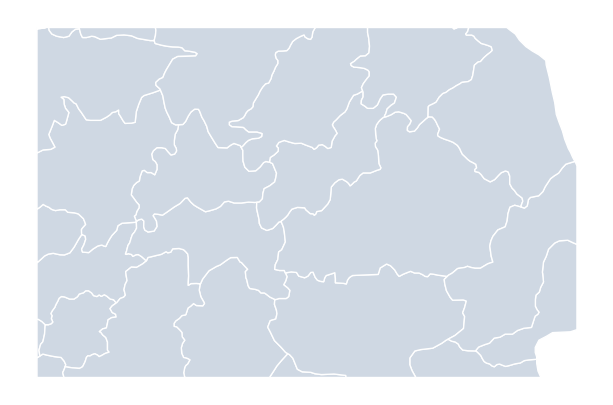

In [2]:
GB_URL = ("https://media.githubusercontent.com/media/wmgeolab/geoBoundaries/9469f09/"
          "releaseData/gbOpen/GRC/ADM3/geoBoundaries-GRC-ADM3.geojson")
gb_file = ROOT / "data" / "boundaries" / "geoBoundaries-GRC-ADM3.geojson"
if not gb_file.exists():
    gb_file.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(GB_URL, gb_file)

aoi_gdf = gpd.GeoDataFrame(geometry=[box(*AOI_BOUNDS)], crs=4326)

muni = gpd.read_file(gb_file)[["shapeName", "geometry"]].rename(columns={"shapeName": "municipality"})
muni = gpd.clip(muni, aoi_gdf)
muni = muni[muni.to_crs(2100).area > 1e6].reset_index(drop=True)      # drop slivers < 1 km²

# Simplify (50 m) so the polygons are light enough to send to Earth Engine
muni_simple = muni.to_crs(2100).simplify(50).to_crs(4326)
muni_ee = geemap.gdf_to_ee(gpd.GeoDataFrame(muni[["municipality"]], geometry=muni_simple))

print(len(muni), "municipalities in the study area")
ax = muni.plot(edgecolor="white", color="#cfd8e3", figsize=(8, 5))
ax.set_axis_off()

## 2. Flood layers and land cover

- **Peak flood**: union of the 12 and 13 September passes (same as notebook 01)
- **Still flooded in late December**: pass of 30 December 2023 (orbit 7), which sees the whole Karla basin (notebook 03).
  Counted **only inside the peak extent**, so that winter rain and wet ploughed fields elsewhere are not mistaken for flood water.
- **ESA WorldCover v200 (2021)**: pre-event land cover, 10 m

For every pixel we build one band per "flooded × land-cover class" and multiply by the pixel area, so a simple **sum per municipality** gives km².

In [3]:
CLASSES = {          # ESA WorldCover codes
    "cropland": 40,
    "grassland": 30,
    "tree_cover": 10,
    "shrubland": 20,
    "built_up": 50,
    "bare": 60,
    "wetland": 90,
}

flood_peak, _ = peak_flood(aoi)
flood_dec, covered_dec = flood_map(aoi, "2023-12-30", "2023-12-31")
lc = ee.ImageCollection("ESA/WorldCover/v200").first().select("Map")

f = flood_peak.unmask(0)
bands = [f.rename("flooded")]
bands += [f.And(lc.eq(code)).rename(f"flooded_{name}") for name, code in CLASSES.items()]
bands += [
    lc.eq(40).rename("cropland_total"),
    flood_dec.unmask(0).And(f).And(lc.eq(40)).rename("cropland_flooded_dec"),   # only inside the peak extent
    covered_dec.unmask(0).And(lc.eq(40)).rename("cropland_seen_dec"),
]
stack = ee.Image.cat(bands).multiply(ee.Image.pixelArea()).divide(1e6).clip(aoi)   # km² per pixel
stack.bandNames().getInfo()

['flooded',
 'flooded_cropland',
 'flooded_grassland',
 'flooded_tree_cover',
 'flooded_shrubland',
 'flooded_built_up',
 'flooded_bare',
 'flooded_wetland',
 'cropland_total',
 'cropland_flooded_dec',
 'cropland_seen_dec']

## 3. Sum per municipality

`reduceRegions` runs the sum for all municipalities in one request.
⏳ If it fails with *Computation timed out*, set `SCALE = 30`.

In [4]:
SCALE = 10

stats = stack.reduceRegions(collection=muni_ee, reducer=ee.Reducer.sum(), scale=SCALE, tileScale=4)
df = pd.DataFrame([feat["properties"] for feat in stats.getInfo()["features"]])

df = df.set_index("municipality").sort_values("flooded_cropland", ascending=False)
df.to_csv(OUT / "flood_impact_by_municipality_raw.csv")
print(f"Total flooded area: {df['flooded'].sum():,.1f} km²  (notebook 01: ~342 km²)")

Total flooded area: 341.8 km²  (notebook 01: ~342 km²)


## 4. Which land was flooded?

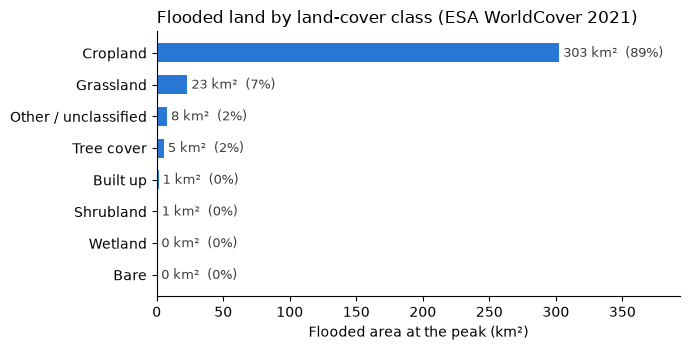

In [5]:
by_class = (df[[f"flooded_{c}" for c in CLASSES]].sum()
            .rename(lambda c: c.replace("flooded_", "").replace("_", " ").capitalize()))
by_class["Other / unclassified"] = df["flooded"].sum() - by_class.sum()
by_class = by_class.sort_values()
share = 100 * by_class / by_class.sum()

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(by_class.index, by_class.values, color="#2a78d6", height=0.6)
for y, (v, p) in enumerate(zip(by_class.values, share.values)):
    ax.text(v + 3, y, f"{v:,.0f} km²  ({p:.0f}%)", va="center", fontsize=9, color="#3d3d3a")
ax.set_xlabel("Flooded area at the peak (km²)")
ax.set_title("Flooded land by land-cover class (ESA WorldCover 2021)", loc="left")
ax.set_xlim(0, by_class.max() * 1.3)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(OUT / "flooded_land_cover.png", dpi=200)
plt.show()

## 5. Impact per municipality

In [6]:
table = pd.DataFrame({
    "Flooded, total (km²)": df["flooded"],
    "Cropland flooded (km²)": df["flooded_cropland"],
    "Cropland flooded (stremmata)": df["flooded_cropland"] * 1000,
    "Share of cropland flooded (%)": 100 * df["flooded_cropland"] / df["cropland_total"],
    "Built-up flooded (km²)": df["flooded_built_up"],
    "Cropland still flooded 30 Dec (km²)": df["cropland_flooded_dec"],
})
# December value only where the 30 Dec pass sees most of the municipality's cropland
seen_dec = df["cropland_seen_dec"] / df["cropland_total"]
table.loc[seen_dec < 0.8, "Cropland still flooded 30 Dec (km²)"] = float("nan")

table = table[table["Flooded, total (km²)"] >= 0.5].round(1)
table.loc["Total"] = table.sum(numeric_only=True).round(1)
table.loc["Total", "Share of cropland flooded (%)"] = round(
    100 * df["flooded_cropland"].sum() / df["cropland_total"].sum(), 1)
table["Cropland flooded (stremmata)"] = table["Cropland flooded (stremmata)"].round(-2).astype(int)
table.to_csv(OUT / "flood_impact_by_municipality.csv")
table

,"Flooded, total (km²)",Cropland flooded (km²),Cropland flooded (stremmata),Share of cropland flooded (%),Built-up flooded (km²),Cropland still flooded 30 Dec (km²)
municipality,,,,,,
Agia,60.3,55.6,55600,54.8,0.1,34.4
Kileler,55.0,51.8,51800,6.5,0.1,27.9
Farkadona,46.9,43.6,43600,26.1,0.1,0.3
Palamas,42.0,40.5,40500,13.4,0.1,0.2
Tempi,46.9,38.5,38500,41.7,0.3,0.1
Rigas Feraios,37.8,27.0,27000,14.7,0.7,25.1
Larissa,29.6,26.7,26700,13.4,0.1,0.1
Trikala,5.7,5.2,5200,2.4,0.0,NaN
Farsala,5.6,5.1,5100,1.1,0.0,0.3


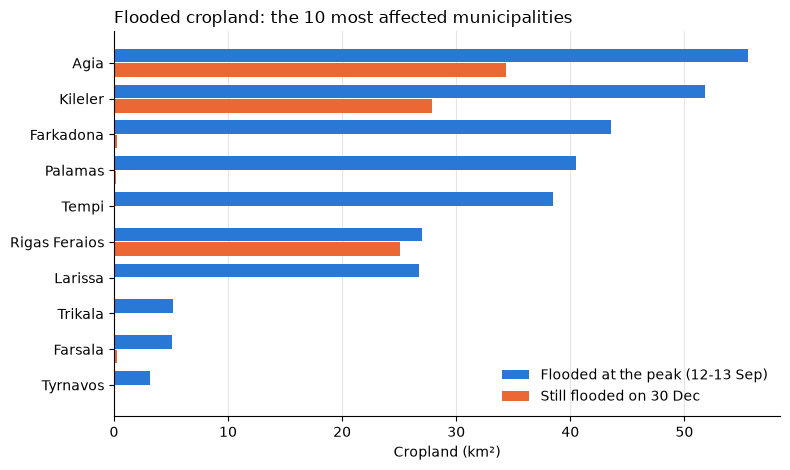

In [7]:
top = table.drop("Total").nlargest(10, "Cropland flooded (km²)").iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 4.8))
y = range(len(top))
ax.barh([i + 0.2 for i in y], top["Cropland flooded (km²)"], height=0.38, color="#2a78d6",
        label="Flooded at the peak (12-13 Sep)")
ax.barh([i - 0.2 for i in y], top["Cropland still flooded 30 Dec (km²)"].fillna(0), height=0.38, color="#eb6834",
        label="Still flooded on 30 Dec")
ax.set_yticks(list(y), top.index)
ax.set_xlabel("Cropland (km²)")
ax.set_title("Flooded cropland: the 10 most affected municipalities", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="x", color="#e6e6e1", lw=0.8)
ax.set_axisbelow(True)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(OUT / "flooded_cropland_by_municipality.png", dpi=200)
plt.show()

## 6. Map: share of each municipality's cropland that was flooded

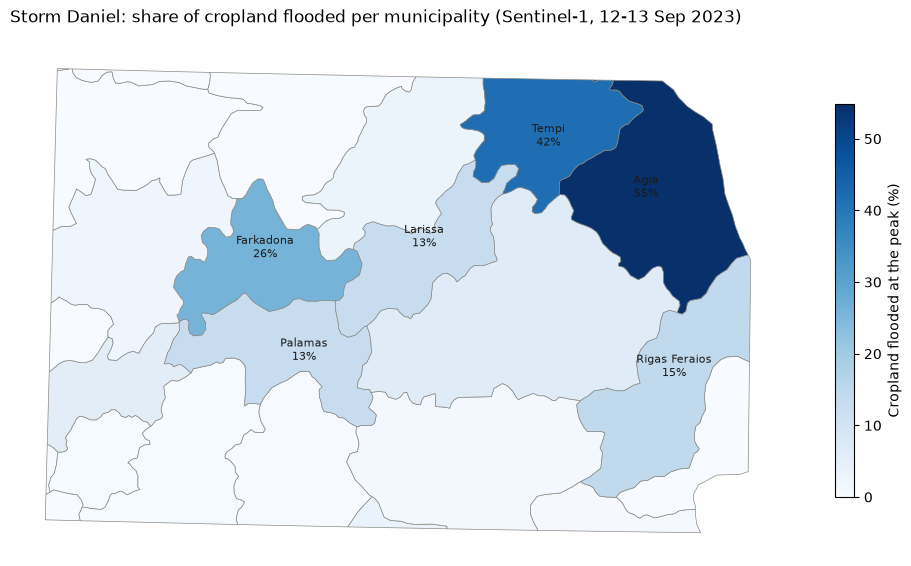

In [8]:
m = muni.merge(table[["Share of cropland flooded (%)"]], left_on="municipality", right_index=True, how="left").to_crs(2100)
m["Share of cropland flooded (%)"] = m["Share of cropland flooded (%)"].fillna(0)

fig, ax = plt.subplots(figsize=(10, 6))
m.plot(column="Share of cropland flooded (%)", cmap="Blues", edgecolor="#8a8a85", linewidth=0.5, ax=ax,
       legend=True, legend_kwds={"label": "Cropland flooded at the peak (%)", "shrink": 0.7})
for _, r in m.nlargest(6, "Share of cropland flooded (%)").iterrows():
    p = r.geometry.representative_point()
    ax.annotate(f"{r['municipality']}\n{r['Share of cropland flooded (%)']:.0f}%", (p.x, p.y),
                ha="center", fontsize=8, color="#1a1a19")
ax.set_title("Storm Daniel: share of cropland flooded per municipality (Sentinel-1, 12-13 Sep 2023)", loc="left")
ax.set_axis_off()
fig.tight_layout()
fig.savefig(OUT / "cropland_flooded_share_map.png", dpi=200)
plt.show()

## 7. Interpretation

- **The flood was an agricultural disaster.** Of the 342 km² flooded at the peak, **~303 km² (89%) was cropland**, about **300,000 stremmata**,
  or 9% of all cropland in the study area. Grassland adds another 23 km².
- **Most affected municipalities** (cropland flooded at the peak): **Agia** (~56 km², 55% of its cropland), **Kileler** (~52 km²),
  **Farkadona** (~44 km²), **Palamas** (~41 km²) and **Tempi** (~39 km², 42% of its cropland).
- **Long-term loss is concentrated around Lake Karla.** By 30 December almost all the cropland in the West and along the Pineios had drained,
  but large areas in **Agia, Kileler and Rigas Feraios** (the Karla basin) were still under water and missed the winter sowing season.
- **Built-up land: only ~1.5 km²**, which is certainly an **underestimate**. Villages such as Metamorfosi and Vlochos were flooded, but in towns
  the water between buildings gives a *bright* radar signal (double bounce) instead of a dark one, so this method cannot see urban flooding.

**Caveats**
- Municipalities are clipped to the study area; municipalities only partly inside it (e.g. Volos, Elassona) are under-counted.
- WorldCover 2021 is a 10 m classification (~75% overall accuracy); "cropland" includes fallow fields.
- SAR misses shallow water among tall crops (notebook 02), so flooded cropland is a **lower bound**.